# 13 Feature-group ablation, 09:00 cutoff

In notebook 12 every model built on an unbiased reference (`ref28`, `refshift`) still ended up 12-16 below actual prices in folds 13-16, so the learned deviation from the reference is too negative there. Which inputs produce it? The Huber model of notebook 11 (alpha 30) on the deviation from `ref28` is refitted with one feature group removed at a time, and with only one group kept. Same folds; reported over all folds and over folds 0-12 / 13-16. This is a diagnostic: the numbers are used to understand the mechanism, not to choose a final feature set (that would be selection on the validation folds).

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
REF = "med28_same"
COMMON = D9[REF].notna() & D9["price"].notna()
print(int(VAL.sum()), "validation rows;", int((VAL & COMMON).sum()), "scored")

22847 validation rows; 22847 scored


## 1. Feature groups

| Group | Columns |
| --- | --- |
| demand | `demand_mw` (spline) |
| wind | `wind_mw`, `emb_wind_mw` (splines) |
| solar | `emb_solar_mw` (spline) |
| seasonal | `doy_sin`, `doy_cos` |
| margin | five `mgn_*` columns |
| history | `med28_same`, `med7_same`, `d2_same`, `level24h`, `level7`, `level28`, `level_gap` |
| calendar | `hour_frac` (periodic spline), weekday dummies, bank holiday, clock-change flag |

The model is Huber regression (alpha 30) on the deviation from `med28_same`, as in notebooks 11 and 12; the forecast is the reference plus the predicted deviation.

In [2]:
GROUPS = {
    "demand": ["demand_mw"], "wind": ["wind_mw", "emb_wind_mw"], "solar": ["emb_solar_mw"],
    "seasonal": ["doy_sin", "doy_cos"],
    "margin": ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"],
    "history": ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"],
    "calendar": ["hour_frac", "weekday", "bank_holiday", "clock_change_day"],
}
SPLINE = {"demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"}

def make_model(keep):
    cols = [c for g in keep for c in GROUPS[g]]
    spl = [c for c in cols if c in SPLINE]
    lin = [c for c in cols if c not in SPLINE and c not in ("hour_frac", "weekday")]
    parts = []
    if spl:
        parts.append(("spl", make_pipeline(SimpleImputer(strategy="median"),
                      SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), spl))
    if "hour_frac" in cols:
        parts.append(("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]))
    if lin:
        parts.append(("lin", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), lin))
    if "weekday" in cols:
        parts.append(("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"]))
    return Pipeline([("pre", ColumnTransformer(parts)), ("est", HuberRegressor(alpha=30, epsilon=1.35, max_iter=300))]), cols

def run_cv(keep):
    pred = pd.Series(np.nan, index=D9.index)
    dev = pd.Series(np.nan, index=D9.index)
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & COMMON]
        va = D9[D9["day"].isin(f["val_days"])]
        m, cols = make_model(keep)
        m.fit(tr[cols], tr["price"] - tr[REF])
        dev.loc[va.index] = m.predict(va[cols])
        pred.loc[va.index] = dev.loc[va.index] + va[REF]
    return pred, dev

def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"]) & COMMON].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9[REF])
ALLG = list(GROUPS)
CONFIGS = {"full": ALLG}
for g in ALLG:
    CONFIGS[f"minus {g}"] = [x for x in ALLG if x != g]
CONFIGS["minus demand, wind, solar"] = [x for x in ALLG if x not in ("demand", "wind", "solar")]
for g in ("demand", "wind", "solar"):
    CONFIGS[f"calendar + history + {g} only"] = ["calendar", "history", g]
CONFIGS["calendar + history only"] = ["calendar", "history"]
print(len(CONFIGS), "configurations")

13 configurations


## 2. Run

Columns: difference to the 28-day baseline (negative is better for MAE and RMSE, positive for hit rates) over all folds and the late folds 13-16; `bias late` is the mean error (forecast minus actual) over folds 13-16; `pred dev late` and `actual dev late` are the mean predicted and the mean actual deviation from `ref28` over those folds (the gap between them is the bias).

In [3]:
RES = {}
FT = {}
t0 = time.time()
for name, keep in CONFIGS.items():
    pred, dev = run_cv(keep)
    ft = fold_table(pred); FT[name] = ft
    late_rows = D9["day"].isin(pd.DatetimeIndex(np.concatenate([folds[k]["val_days"].values for k in range(13, 17)]))) & COMMON
    d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
    RES[name] = {"dMAE all": d["MAE"].mean(), "dMAE 0-12": d["MAE"].loc[:12].mean(), "dMAE late": d["MAE"].loc[13:].mean(),
                 "dRMSE all": d["RMSE"].mean(), "dRMSE late": d["RMSE"].loc[13:].mean(),
                 "dHitTop all": d["hit_top8"].mean(), "dHitBot all": d["hit_bot8"].mean(),
                 "bias late": ft["bias"].loc[13:].mean(), "bias f16": ft["bias"].loc[16],
                 "pred dev late": dev[late_rows].mean(), "actual dev late": (D9["price"] - D9[REF])[late_rows].mean()}
    print(f"{name:34s} {time.time() - t0:4.0f}s")
R = pd.DataFrame(RES).T
print(R.round(2).to_string())

full                                  8s


minus demand                         14s


minus wind                           20s


minus solar                          27s


minus seasonal                       34s


minus margin                         41s


... (3 outputs left out)

calendar + history + demand only     59s


calendar + history + wind only       63s


calendar + history + solar only      67s


calendar + history only              69s
                                  dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitBot all  bias late  bias f16  pred dev late  actual dev late
full                                 -1.90      -2.42      -0.24      -4.12       -1.82         0.03         0.05     -11.77    -15.35         -11.10             0.68
minus demand                         -1.29      -1.68      -0.01      -3.39       -1.42         0.01         0.02     -10.61    -13.06          -9.93             0.68
minus wind                           -1.30      -1.90       0.64      -3.19       -0.79         0.02         0.03     -11.53    -16.95         -10.85             0.68
minus solar                          -1.85      -2.27      -0.49      -4.19       -2.35         0.03         0.03     -11.56    -15.00         -10.88             0.68
minus seasonal                       -1.94      -2.44      -0.34      -4.15       -1.93         0.03         0.05     -11.67

## 3. Predicted against actual deviation over time

Mean predicted and mean actual deviation from the reference by fold, for the full model.

      median price  mean predicted dev  mean actual dev  median predicted dev  median actual dev
fold                                                                                            
0             79.4               -12.5              1.0                  -9.0                1.3
1             64.7               -12.6            -12.0                  -9.2               -7.2
2             83.5               -13.7             -2.4                 -12.3                3.1
3             70.0                -4.1             -2.5                  -0.9               -1.0
4             72.8                -1.6              2.3                   3.9                1.4
5             66.2                 0.7             -7.8                   4.2                1.4
6             76.1                -6.1             -5.8                   4.6               -0.9
7             71.8                11.3              0.1                  18.7                1.1
8             74.5            

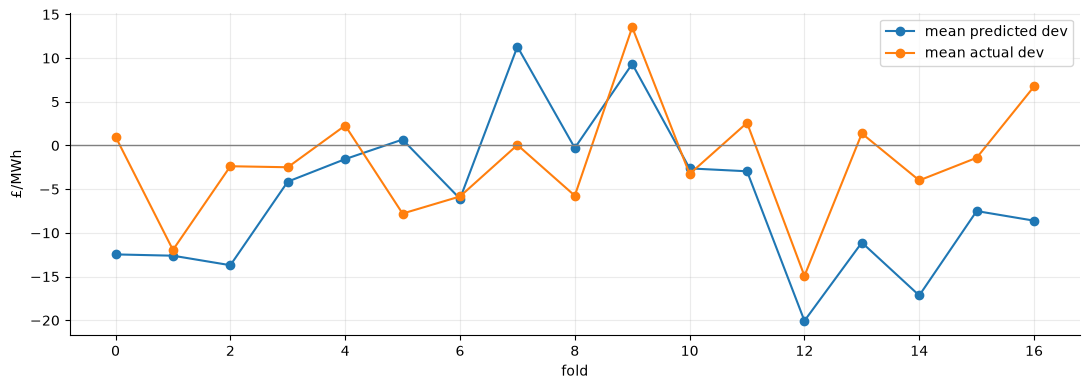

In [4]:
pred, dev = run_cv(ALLG)
rows = []
for f in folds:
    m = D9["day"].isin(f["val_days"]) & COMMON
    rows.append({"fold": f["fold"], "median price": D9.loc[m, "price"].median(),
                 "mean predicted dev": dev[m].mean(), "mean actual dev": (D9["price"] - D9[REF])[m].mean(),
                 "median predicted dev": dev[m].median(), "median actual dev": (D9["price"] - D9[REF])[m].median()})
Dv = pd.DataFrame(rows).set_index("fold")
print(Dv.round(1).to_string())
Dv[["mean predicted dev", "mean actual dev"]].plot(marker="o")
plt.axhline(0, color="grey", lw=1); plt.ylabel("\u00a3/MWh"); plt.xlabel("fold")
plt.tight_layout(); plt.show()

## Findings (Huber, deviation from `ref28`, 09:00; 13 configurations; all numbers diagnostic)

- **The negative deviation in the recent folds comes mainly from the `history` group.** In folds 13-16 the full model predicts a mean deviation of -11.1 from the reference where the actual mean deviation is +0.7 (bias -11.8). Removing `history` (the level and profile terms) cuts the late bias to -3.7 and gives a late MAE 1.2 better than the baseline (full model: 0.2 better) and a late RMSE 3.1 better (full: 1.8). Removing any other single group (demand, wind, solar, seasonal, margin, calendar) leaves the late bias at -10.6 to -12.1.
- **The cost of removing `history` is in the earlier folds.** Over folds 0-12 the MAE gain falls from 2.4 to 1.1, and the hit-rate gains fall from +0.03/+0.05 to +0.01/+0.02. So the level terms help in the earlier regime and hurt in the recent one: a sign that they carry mean reversion toward the training-period price level (a model trained when prices were lower pulls forecasts back toward that level when the reference is high).
- **The weather groups interact with it.** Demand-only on top of calendar and history is the worst case (late bias -16.5, late MAE +2.1 worse than the baseline); wind-only is the best (late bias +3.2, late MAE 1.05 better, but only 1.1 better over folds 0-12 too, and hit-rate gains of just +0.01). Removing demand, wind and solar together gives a late bias of -8.6, so calendar plus history alone is also biased down (-2.3 without weather, -8.6 here with margin and seasonal terms).
- **Leading explanation (a hypothesis, not tested).** The demand, wind and solar forecasts are used as absolute levels, and so carry seasonal information that the reference already contains. In summer 2026 the forecasts say low demand and high solar, the model applies the winter-trained relationship to those values and subtracts price, while the reference (which uses the last 28 days) is already at the summer level. A fix that fits this: use each forecast relative to its own recent typical value at the same clock time (for example the forecast minus the mean of the same period's point-in-time forecasts over D-29..D-2), so that only the day's departure from normal drives the deviation.
- **Do not choose a feature set from this table.** The ablation was run on the validation folds, so picking the best row would be selection on them. The mechanism above should be tested as a pre-specified change (anomaly features, and level terms removed or limited), and judged across all folds and the late folds together.
